# 01 · What is a digital twin? A heated rod in 1D
**Level: Beginner** · ~10 min · *Track: Foundations*

A **digital twin** is a computer model of a real physical asset that is **kept in sync with that
asset through data**, so it can tell you things you cannot measure directly and predict what will
happen next.

| Ingredient | In this course |
|---|---|
| **Physical asset** | a metal rod being heated (1D), a contaminated tank or room (2D) |
| **Physics model** | a partial differential equation (PDE) such as the heat equation |
| **Sensors** | a few thermometers or concentration probes, with noise |
| **Synchronisation** | calibration, Kalman filters, ensemble methods, PINNs |
| **Decisions** | forecasts, alarms, what-if scenarios |

The fields we model are **spatio-temporal**: a value $u(x, t)$ at every point in space and every
instant in time. This notebook builds the first ingredient, the **physics model**, from scratch
with plain NumPy.

**You will learn**
1. the heat equation and what each term means
2. how to discretise it in space and time (finite differences)
3. why time steps have a stability limit
4. how to visualise a space-time field (heatmap, profiles, animation)

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
from dtwin import viz
viz.set_style()

## 1. The physics: the heat equation

$$\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2} + f(x,t), \qquad x\in[0,L]$$

* $u(x,t)$: temperature along the rod
* $\alpha$: thermal diffusivity (how fast heat spreads, m²/s)
* $f(x,t)$: a heat source (a heater clamped to the rod)
* boundary conditions: both ends held at $u=0$ (ice baths)

The curvature $u_{xx}$ drives the dynamics: where the profile is a hump (negative curvature),
temperature drops; in a valley it rises. Heat flows from hot to cold and smooths everything out.

## 2. Discretising: from a PDE to arrays
Put $n_x$ grid points on the rod with spacing $\Delta x$, and step time by $\Delta t$.
Replacing derivatives with finite differences gives the **explicit FTCS** scheme
(Forward in Time, Central in Space):

$$u_i^{k+1} = u_i^k + r\,(u_{i+1}^k - 2u_i^k + u_{i-1}^k) + \Delta t\, f_i^k, \qquad r = \frac{\alpha\,\Delta t}{\Delta x^2}$$

Every new value depends only on its neighbours at the previous step. That is one line of NumPy:

In [2]:
def ftcs(u0, alpha, dx, dt, n_steps, source=None, x=None):
    """Explicit finite differences for u_t = alpha u_xx + f, ends fixed."""
    U = np.empty((n_steps + 1, u0.size))
    U[0] = u0
    r = alpha * dt / dx**2
    for k in range(n_steps):
        u = U[k].copy()
        u[1:-1] += r * (U[k, 2:] - 2 * U[k, 1:-1] + U[k, :-2])
        if source is not None:
            u[1:-1] += dt * source(x, k * dt)[1:-1]
        U[k + 1] = u
    return U

L, nx, alpha = 1.0, 101, 0.01
x = np.linspace(0, L, nx)
dx = x[1] - x[0]
dt = 0.4 * dx**2 / alpha          # r = 0.4
n_steps = int(10.0 / dt)
t = np.arange(n_steps + 1) * dt
print(f"dx = {dx:.3f}, dt = {dt:.4f}, r = {alpha*dt/dx**2:.2f}, steps = {n_steps}")

dx = 0.010, dt = 0.0040, r = 0.40, steps = 2500


## 3. Sanity check against an exact solution
With no source and $u(x,0)=\sin(\pi x/L)$ the solution is known:
$u(x,t) = e^{-\alpha\pi^2 t/L^2}\sin(\pi x/L)$. **Always verify a solver before trusting it**:
a twin built on a wrong model just reproduces the errors of that model.

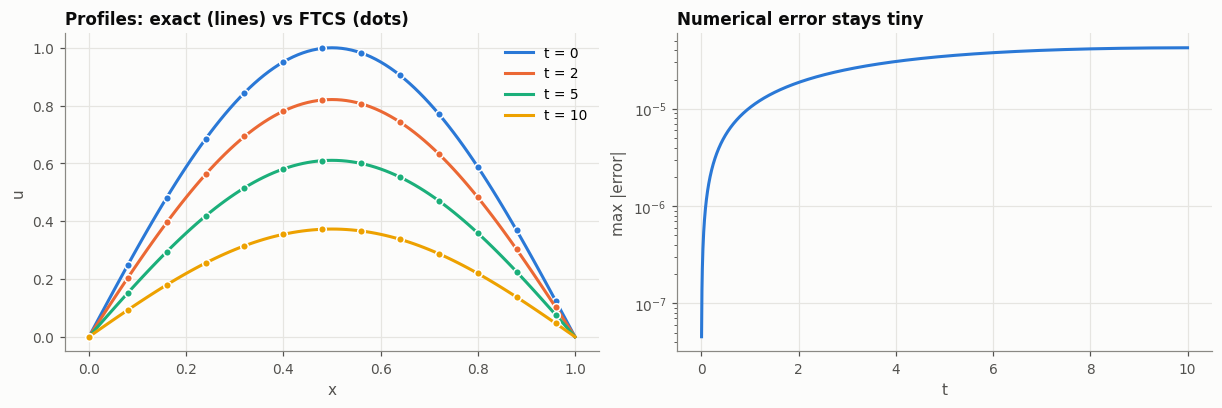

In [3]:
u0 = np.sin(np.pi * x / L)
U_num = ftcs(u0, alpha, dx, dt, n_steps)
U_exact = np.exp(-alpha * np.pi**2 * t[:, None] / L**2) * np.sin(np.pi * x / L)[None]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
ax = axes[0]
for i, tk in enumerate([0, 2, 5, 10]):
    k = int(round(tk / dt))
    ax.plot(x, U_exact[k], color=viz.SERIES[i], lw=2, label=f"t = {tk}")
    ax.plot(x[::8], U_num[k, ::8], "o", color=viz.SERIES[i], ms=5, mec="white")
ax.set(xlabel="x", ylabel="u", title="Profiles: exact (lines) vs FTCS (dots)")
ax.legend()
axes[1].semilogy(t[1:], np.abs(U_num - U_exact).max(1)[1:], color=viz.TWIN)
axes[1].set(xlabel="t", ylabel="max |error|", title="Numerical error stays tiny")
plt.show()

## 4. Stability: why $\Delta t$ cannot be too large
The explicit scheme is only stable when $r = \alpha\Delta t/\Delta x^2 \le 1/2$. Push past it and
short-wavelength errors grow exponentially: the simulation explodes.
This is the first engineering constraint of a twin: **finer grids force smaller time steps**,
which is one reason we later move to implicit schemes and reduced-order models.

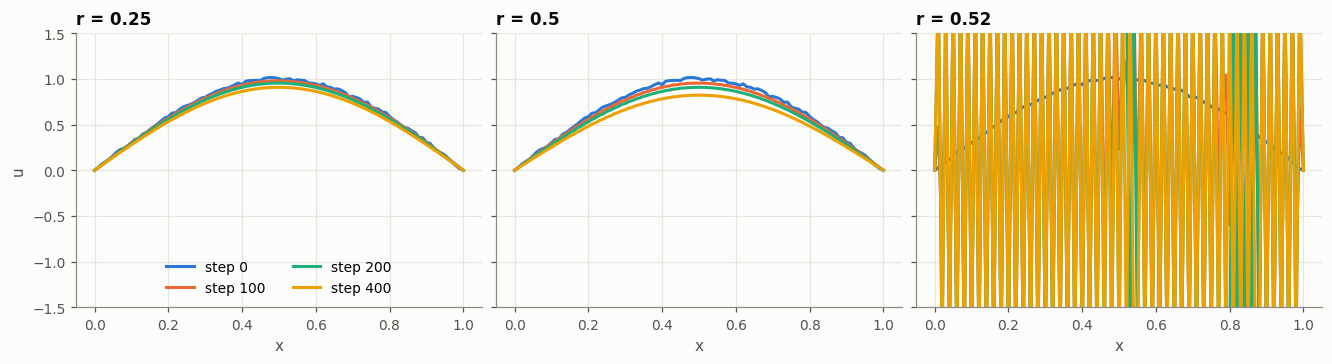

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), constrained_layout=True, sharey=True)
u0_noisy = u0 + 0.01 * np.random.default_rng(0).standard_normal(nx)
u0_noisy[[0, -1]] = 0
for ax, r in zip(axes, [0.25, 0.5, 0.52]):
    dtr = r * dx**2 / alpha
    Ur = ftcs(u0_noisy, alpha, dx, dtr, 400)
    for i, k in enumerate([0, 100, 200, 400]):
        ax.plot(x, np.clip(Ur[k], -2, 2), color=viz.SERIES[i], label=f"step {k}")
    ax.set(title=f"r = {r}", xlabel="x", ylim=(-1.5, 1.5))
axes[0].set_ylabel("u")
axes[0].legend(loc="lower center", ncol=2)
plt.show()

## 5. A heated rod: the "physical asset" of the 1D track
Now clamp a heater at $x=0.3$ that switches on at $t=1$, and add a second, weaker heater at
$x=0.75$ that runs from $t=4$ to $t=7$. Start from a cold rod.

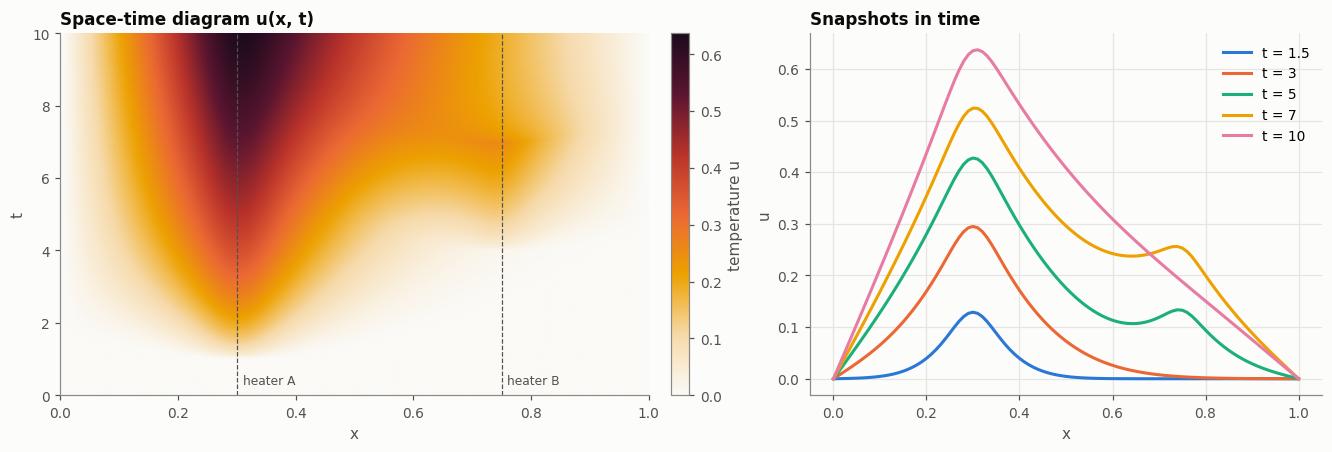

In [5]:
def heaters(x, t):
    f = np.zeros_like(x)
    if t >= 1.0:
        f += 0.6 * np.exp(-((x - 0.3) / 0.04) ** 2)
    if 4.0 <= t < 7.0:
        f += 0.4 * np.exp(-((x - 0.75) / 0.03) ** 2)
    return f

U = ftcs(np.zeros(nx), alpha, dx, dt, n_steps, source=heaters, x=x)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.15, 1]})
viz.spacetime(axes[0], U, x, t, label="temperature u")
axes[0].set_title("Space-time diagram u(x, t)")
for xs, lbl in [(0.3, "heater A"), (0.75, "heater B")]:
    axes[0].axvline(xs, color=viz.INK2, lw=0.8, ls="--")
    axes[0].text(xs + 0.01, 0.3, lbl, color=viz.INK2, fontsize=8)
ax = axes[1]
for i, tk in enumerate([1.5, 3, 5, 7, 10]):
    ax.plot(x, U[int(round(tk / dt))], color=viz.SERIES[i], label=f"t = {tk}")
ax.set(xlabel="x", ylabel="u", title="Snapshots in time")
ax.legend()
viz.save(fig, "01_heated_rod.png")
plt.show()

**How to read a space-time diagram:** each horizontal slice is the rod at one instant, each
vertical slice is the history of one point. The plume widening upward is diffusion; its brightness
is the heater's power competing with cooling through the cold ends.

## 6. Watching it evolve

In [6]:
idx = np.linspace(0, n_steps, 60).astype(int)
anim = viz.animate_1d(x, [U[idx]], t[idx], labels=["rod temperature"], colors=[viz.ORANGE],
                      title="Heated rod", ylabel="u")
HTML(anim.to_jshtml())

## 7. Energy budget: a physical consistency check
Total heat $E(t)=\int u\,dx$ changes by what the heaters inject minus what leaks through the ends:
$\;dE/dt = \int f\,dx + \alpha\,[u_x(L) - u_x(0)]$. Checking conservation laws is a cheap way to
catch bugs, and later it becomes a **physics-based anomaly detector**.

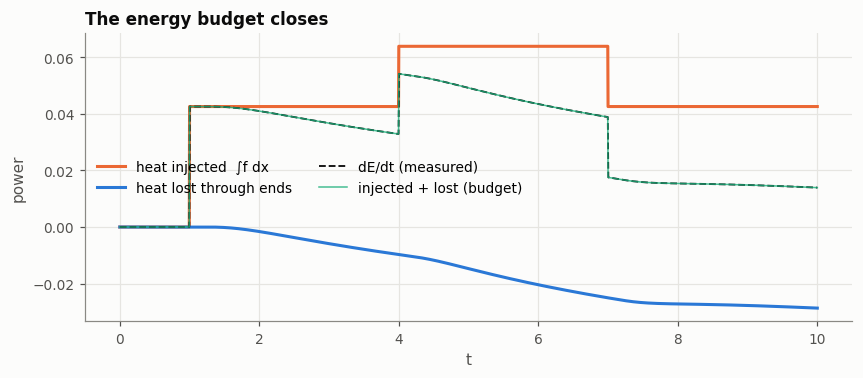

In [7]:
E = np.trapezoid(U, x, axis=1)
inj = np.array([np.trapezoid(heaters(x, tk), x) for tk in t])
leak = alpha * ((U[:, -1] - U[:, -2]) - (U[:, 1] - U[:, 0])) / dx
dEdt = np.gradient(E, dt)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(t, inj, color=viz.ORANGE, label="heat injected  ∫f dx")
ax.plot(t, leak, color=viz.BLUE, label="heat lost through ends")
ax.plot(t, dEdt, color=viz.INK, lw=1.2, ls="--", label="dE/dt (measured)")
ax.plot(t, inj + leak, color=viz.AQUA, lw=1, alpha=0.8, label="injected + lost (budget)")
ax.set(xlabel="t", ylabel="power", title="The energy budget closes")
ax.legend(ncol=2)
plt.show()

## Recap and what's next
* A PDE + a grid + a time stepper = a **simulator** (half of a twin).
* Verify with exact solutions and conservation laws; respect stability limits.
* A simulator alone is *not* a twin: it knows nothing about the *actual* rod. Its
  diffusivity, heaters and initial state may all be wrong.

**Next (02):** put virtual sensors on the rod and see what we can, and cannot, learn from them.

**Exercises**
1. Switch to insulated ends (`u[0]=u[1]`, `u[-1]=u[-2]` after each step). How does the energy budget change?
2. Halve $\Delta x$. How many more steps do you need for the same simulated time? Why?
3. Add a heater whose power oscillates as $\sin(2\pi t/2)$. What happens far from the heater?